# LASSI - Serial

**OLLAMA API** + **Argo Gateway API** + **Cerebras API** Jupyter Notebook version

+ ***Post LASSI-Judge version with data collection for pass@k and energy_reduction@k***
+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

NVIDIA GPU power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

Added support for AMD GPU device measurements and HIP code (ROCm)

--- 
**THIS VERSION:** Serial C code refactoring for speedup

In [1]:
from lassi.gpu_detector import detect_gpu_vendors

# Detect available GPUs
vendors = detect_gpu_vendors()
if not vendors:
    print("❌ No GPUs detected! LASSI requires GPU hardware.")
    raise SystemExit("Pipeline stopped - no GPU hardware found")

detected_vendor = vendors[0]['vendor']
gpu_count = vendors[0]['count']
print(f"🔍 Detected: {detected_vendor.upper()} with {gpu_count} GPU(s)")

# Vendor-specific initialization
if detected_vendor == "nvidia":
    # NVIDIA-specific setup
    import pynvml
    pynvml.nvmlInit()
    print("NVIDIA Driver Version:", pynvml.nvmlSystemGetDriverVersion())
    pynvml.nvmlShutdown()
    
    # Show NVIDIA system info
    !nvidia-smi
    !nvcc --version
    
elif detected_vendor == "amd":
    # AMD-specific setup
    from lassi.amd_power import amd_report_gpu_memory
    
    # Show AMD system info
    !rocminfo | head -20
    !rocm-smi
    !hipcc --version
    
print(f"\n✅ {detected_vendor.upper()} GPU environment ready for LASSI!")

🔍 Detected: NVIDIA with 1 GPU(s)
NVIDIA Driver Version: 570.195.03
Tue Nov 25 00:11:34 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.195.03             Driver Version: 570.195.03     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX 5000 Ada Gene...    Off |   00000000:01:00.0 Off |                  Off |
| N/A   41C    P8              3W /   80W |      14MiB /  16376MiB |      0%      Default |
|                                         |                        |     

## Setup

In [2]:
import os
import json
import csv
import time
import shutil
from datetime import datetime
from zoneinfo import ZoneInfo

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v3
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline_v3
%aimport lassi.get_power
%aimport lassi.argostream_curl
%aimport lassi.code_manager

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [3]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    PolyBenchC
    -- 3mm


    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["10000", "1024", "1"] ["8192", "8192", "500"]   # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]
    -- murmurhash3 ["750000, 500"]
    -- chacha20 ["300000"]
    -- jaccard ["1024, 512, 1000"]
    -- keogh ["256", "22500000", "100"]
    -- floydwarshall ["2048", "100", "256"]
    -- extrema ["750"]
    -- threadfence ["100", "250000000"]
    -- all-pairs-distance ["10000"]
    -- marchingCubes ["100"]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]

    Miniapps:
    -- miniMDock ["-lfile", "./input/7cpa/7cpa_ligand.pdbqt", "-nrun 500"]
    -- XSBench ["-m", "event", "-l", "1700000000"]
    
    """

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # Enter source application to process through LASSI
    source_collection = "PolyBenchC"  # "Miniapps" "HeCBench"
    source_app = "3mm"  # "miniMDock" jacobi
    make_script = False  # Used only for Miniapps
    build_script = False  # False (for HeCBench) Use for Altis only
    

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    3. miniMDock/bin/
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    lines_of_code = source_apps[source_collection][source_app]["code_lines"]
    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "C"
    target_lang = "C"

    if make_script:
        app_name = source_app  # app_folder_name
        file_name = "Main"  # kernels
    else:
        if source_lang == "C":
            app_name = source_app
        else:
            app_name = "mt_" + app_folder_name + "-cuda_main"
        file_name = ""

    test_code_first = True  # True or False
    verifyprompt = True  # True or False -- Print out LLM prompt in stdout to preview
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False
    run_code_analysis = False  # True or False
    
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2, v3
    use_self_prompting = False  # True or False -- NOT USED IN v2, v3
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2, v3
    

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = False  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = False  # True or False
    yes_runtime_feedback = True

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            if source_app == "miniMDock":
                code_compiler = "make"
                code_compiler_kwds = "API=CUDA DEVICE=GPU CARD=NVIDIA NUMWI=64"
            elif source_app == "XSBench":
                code_compiler = "cuda/make"
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
            # -arch=sm_89 for RTX 5000
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "C":
        code_compiler = "gcc"
        code_compiler_kwds = "-O3 -I source_codes/PolyBenchC-4.2.1/utilities -I source_codes/PolyBenchC-4.2.1/linear-algebra/kernels/" + source_app + " source_codes/PolyBenchC-4.2.1/utilities/polybench.c -DPOLYBENCH_TIME -DEXTRALARGE_DATASET"
        context_knowledge_selection = "c_serial"
    elif source_lang == "OMP":
        # For A100 on Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        # !! TODO - REVIEW: code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc80"  # "-fopenmp -O3 -c"
        # For RTX 5000 Ada on Linux x86_64:
        # code_compiler = "/opt/nvidia/hpc_sdk/Linux_x86_64/25.7/compilers/bin/nvc++" # "g++"
        # code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc89"  # "-fopenmp -O3"
        context_knowledge_selection = "omp"
    elif source_lang == "HIP":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            if source_app == "miniMDock":
                code_compiler = "make"
                code_compiler_kwds = "API=HIP DEVICE=GPU CARD=AMD NUMWI=64 HIP_PATH=/opt/rocm-6.3.3"
            elif source_app == "XSBench":
                code_compiler = "hip/make"
            else:
                code_compiler_kwds = ""
        else:
            code_compiler = "hipcc"
            code_compiler_kwds = "-std=c++14 -Wall -O3 --amdgpu-target=gfx908"
        if yes_power_feedback:
            context_knowledge_selection = "hip_optimization_summary"
            context_fewshot_examples = "hip_c_few_shot_examples"
        else:
            context_knowledge_selection = "hip"  # TODO

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1
        # ****************************
        # ---> EXPERIMENT UPDATE FIELD - Now, automated:
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto4mini"  # (max token = 128000)
    # model_coder = "gpto4mini"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 200000)
    # model_coder = "gpt4olatest"  # (max token = 200000)
    model = "gpto4mini"
    model_coder = "gpto4mini"
    model_judge = "gpt41"  # (max token = 200000)

    # -- FROM CEREBRAS
    # model = "gpt-oss-120b"
    # model_judge = "gpt-oss-120b"
    # model_coder = "qwen-3-coder-480b"
    
    # -- FROM OLLAMA
    # model = "devstral:24b" # (max token = 128000)
    # model_coder = "devstral:24b" # (max token = 128000)
    # model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
    # model = "qwen3:latest"
    # model_coder = "qwen3:latest"
    # model_judge = "qwen3:latest"  # (max token = 40960)
    # model_coder = "qwen3-coder:30b"  # context 262144
    # model = "gpt-oss:20b"
    # model_judge = "gpt-oss:20b"
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt5", "gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpt4olatest", "gpt41",
                 "gpto1preview", "gpto1mini", "gpto3mini", "gpto4mini", "claudesonnet4"]:
        llm_source = "argo"
    elif model in ["gpt-oss-120b", "qwen-3-coder-480b"]:
        llm_source = "cerebras"
    elif ("GGUF" in model and "hf.co" not in model):
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "testSerial1125_" + model_coder + "_" + app_folder_name + "_ee_" + detected_vendor.upper()  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    """
    [5] SET DATA COLLECTION CONFIGURATION
    """
    # Data spreadsheet column headers
    DATAFIELDNAMES = [
        "trial_number",
        "timestamp",
        "experiment",
        "gpu_vendor",
        "app_name",
        "code_line_count",
        "llm",
        "llm_coder",
        "llm_judge",
        "source_v0_energy_J",
        "source_v0_avg_power_W",
        "source_v0_runtime_s",
        "base_v1_energy_J",
        "base_v1_avg_power_W",
        "base_v1_runtime_s",
        "base_v1_valid",
        "base_v1_energy_diff",
        "base_v1_avg_power_diff",
        "base_v1_runtime_diff",
        # "base_v1_optimization_methods",
        # "base_v2_energy_J",
        # "base_v2_avg_power_W",
        # "base_v2_runtime_s",
        # "base_v2_valid",
        # "base_v2_selfcorrections",
        # "base_v2_energy_diff",
        # "base_v2_avg_power_diff",
        # "base_v2_runtime_diff",
        # "base_v2_optimization_methods",
        "lassiee_energy_J",
        "lassiee_avg_power_W",
        "lassiee_runtime_s",
        "lassiee_valid",
        "lassiee_version",
        "lassiee_llm_temp",
        "lassiee_selfcorrections",
        "lassiee_eeiterations",
        "lassiee_energy_diff",
        "lassiee_avg_power_diff",
        "lassiee_runtime_diff",
        "lassiee_optimization_methods",
        "total_selfcorrections",
        "total_eeiterations",
        "pipeline_runtime_min"
    ]
    
    return (app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, run_code_analysis, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, yes_runtime_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
            verifyprompt, DATAFIELDNAMES, detected_vendor.upper())

# EXPERIMENTAL DATA COLLETION MANAGEMENT
def init_data_collection(dir_path, DATAFIELDNAMES, filename="lassi-ee_pipeline_data.csv"):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=DATAFIELDNAMES)
            writer.writeheader()
    return fp

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***

input_code_folder:  PolyBenchC-4.2.1/linear-algebra/kernels/3mm/

***** EXPERIMENT CONFIGURATION SUMMARY *****

GPU Vendor: NVIDIA
Date-time: 11-25-2025_t00_11_35
Application: linear-algebra/kernels/3mm

EE Refactoring: C_ee

LLM Source: argo
Model: gpto4mini
Model coder: gpto4mini
Model judge: gpt41
System Prompt Index: C
Code file template: generated_codes/argo_gpto4mini/promptset_C/3mm_ee_refactorcode_C_exptestSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA

LLM System Prompt: 

Key not found

Power measurement: False



***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) ***** Trial #: 1



----- WELCOME TO PIPELINE v3! CODE -----

🔍 Detected GPU vendor: NVIDIA

----- GPU Memory Status:
 GPU 0: 435 MiB used, 15940 MiB free, 16376 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 5.75 W, P8


*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


----- SOURCE CODE: Test compile and execute --

Waiting for the system to settle down for 1 seconds...: 100%|██████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/source_codes/PolyBenchC-4.2.1/linear-algebra/kernels/3mm/3mm
initial_dir:  /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE
directory_path:  /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/source_codes/PolyBenchC-4.2.1/linear-algebra/kernels/3mm
executable:  3mm
Working directory: /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/source_codes/PolyBenchC-4.2.1/linear-algebra/kernels/3mm
Execute command: ['./3mm', '']

running: executable -  3mm

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Program execution runtime: 36.829967

----- < END: Standard Output > -----


Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 36.9
GPU power data has been written to idle__gpu_net_power_results.csv


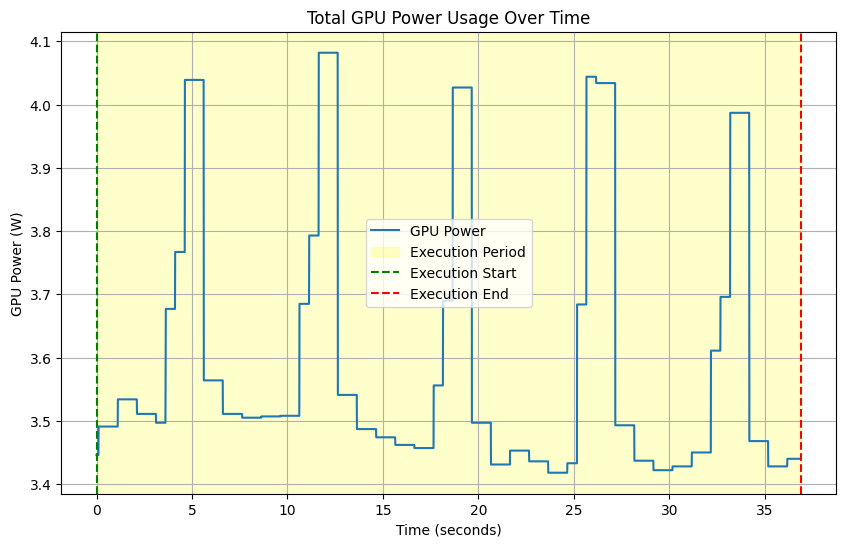

Start time: 0 -- End time: 36.897
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000037 kWh
  0.0367 Wh
  132.26 J
Average GPU power: 3.58 W +/- 0.21 
 with sample standard deviation.
Total Energy During Exe Runtime:   132.26 J
Code execution duration:  36.90 seconds
----------------------------------------------------------------------------------------------------------------------------------------

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


----- STARTING STAGE 1: BASE LLM REFACTORING WITHOUT SELF-CORRECTION  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***

----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt token count, excluding code): 1717


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C programmer. Your goal is to refactor 



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
saving to file_path:  /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/generated_codes/experiment/testSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA__11-25-2025_t00_11_35/3mm_ee_refactorcode_C_exptestSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA_11-25-2025_t00_11_35_Trial1.c
/home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE
Compile command: ['gcc', '-O3', '-I', 'source_codes/PolyBenchC-4.2.1/utilities', '-I', 'source_codes/PolyBenchC-4.2.1/linear-algebra/kernels/3mm', 'source_codes/PolyBenchC-4.2.1/utilities/polybench.c', '-DPOLYBENCH_TIME', '-DEXTRALARGE_DATASET', '/home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/generated_codes/experiment/testSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA__11-25-2025_t00_11_35/3mm_ee_refactorcode_C_exptestSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVI

Waiting for the system to settle down for 5 seconds...: 100%|██████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/generated_codes/experiment/testSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA__11-25-2025_t00_11_35/3mm_ee_refactorcode_C_exptestSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA_11-25-2025_t00_11_35_Trial1
initial_dir:  /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE
directory_path:  /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/generated_codes/experiment/testSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA__11-25-2025_t00_11_35/3mm_ee_refactorcode_C_exptestSerial1125_gpto4mini_linear-algebra/kernels
executable:  3mm_ee_NVIDIA_11-25-2025_t00_11_35_Trial1
Working directory: /home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/generated_codes/experiment/testSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA__11-25-2025_t00_11_35/3mm_ee_refactorcode_C_exptestSerial1125_gpto4mini_linear-algebra/kernels
Execute command: ['./3mm_ee_NVIDIA_11-25-2025_t00_11_35_Trial1', '']

runni



----- LLM RESPONSE: code validation judge -----



Let's carefully evaluate the REFACTORED CODE against the SOURCE CODE for both **functional equivalence** and **standard output equivalence**.

---

## 1. Functional Equivalence

### **Initialization**

- Both codes use the same `init_array` function, initializing arrays A, B, C, D identically.

### **Computation**

#### **SOURCE CODE**
- Performs three matrix multiplications:
  - `E = A * B`
  - `F = C * D`
  - `G = E * F`
- Each multiplication is performed with three nested loops in the canonical i-j-k order.

#### **REFACTORED CODE**
- Performs the same three matrix multiplications, but uses **cache blocking** (tiling) to improve memory locality and performance.
- The blocking sizes are defined as macros (BS_I, BS_J, etc.), and the loops are split into blocks, but the mathematical operations are unchanged.
- The order of computation and the accumulation logic (`+=`) are preserved.
- The code zero-initializes E, F, G before their respective multiplications, matching the original logic.

#### **Correctness of Blocking**
- The blocking does not change the mathematical result; it only changes the order in which elements are computed and accumulated.
- The use of `min()` ensures that the blocks do not exceed array bounds.
- The inner logic (register temporaries for Aik, Cik, Eik) is a performance optimization but does not affect correctness.

### **Output Printing**

- Both codes use the same `print_array` function, which prints the output matrix G in the same format.

### **Dead Code Elimination Prevention**

- Both codes call `polybench_prevent_dce(print_array(...))` to ensure output is printed and not optimized away.

### **Memory Management**

- Both codes allocate and free arrays identically.

### **Conclusion on Functionality**

- The REFACTORED CODE performs the same mathematical operations, on the same data, and prints the same output.
- The only difference is the use of cache blocking for performance, which does not affect the results.

---

## 2. Standard Output Equivalence

### **Program Output**

#### **SOURCE CODE**
```
Program execution runtime: 36.829967
```
#### **REFACTORED CODE**
```
Program execution runtime: 5.458959
```
- The runtime is much lower in the refactored version, which is expected due to cache blocking.

### **Printed Matrix G**

- Both codes use the same printing logic, so the output format and layout are preserved.
- Minor differences in numerical values could occur due to floating-point accumulation order, but these are acceptable and expected in performance-optimized code, as per the instructions.

### **Formatting**

- The output includes the runtime and the matrix G in the same format.

---

## 3. Metrics

- The REFACTORED CODE is significantly faster (5.52s vs 36.90s), which is the intended effect of cache blocking.

---

## 4. Minor Acceptable Differences

- Floating-point accumulation order may cause very minor differences in the output values, but this is acceptable and does not affect the functional equivalence.
- The output layout and content are preserved.

---

## **Final Conclusion**

**Reasoning:**  
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- The printed output is nearly exactly equivalent in layout and content, with only the runtime differing due to improved performance.
- Any minor numerical differences are consistent with the intended purpose and are reasonable.

**Verdict:**  
**VALID**

... (52 outputs left out)



----- LLM RESPONSE: code comparison -----



The refactored version differs from the original in the following energy‐related ways:

1. Zeroing out E, F, and G  
   - SOURCE: three explicit nested loops to set each element to zero.  
   - REFACTORED: single memset calls for each matrix, leveraging a highly optimized library routine instead of manual per‐element stores.

2. Cache‐blocking (tiling)  
   - SOURCE: straightforward triple‐nested loops over the full dimensions for each matrix multiplication.  
   - REFACTORED: introduces block loops (ii, jj, kk, ll, mm) with block sizes BS_I…BS_M (all =64) to operate on sub‐tiles that fit better in cache, reducing memory traffic.

3. Loop reordering and register reuse  
   - SOURCE: inner loop directly accumulated A[i][k] * B[k][j].  
   - REFACTORED: hoists A[i][k], C[i][k], and E[i][k] into a register variable (Aik, Cik, Eik) before the innermost j‐loop, cutting down on repeated loads.

4. Utility macros  
   - Addition of a simple min(a,b) macro to bound the block edges cleanly, instead of computing loop limits in user code.

All these changes preserve the original output but improve spatial and temporal locality, reduce the number of memory operations, and delegate bulk zeroing to optimized library code—thus lowering overall energy consumption and power.

[OPTIMIZATION LIST]
memset zero‐initialization  
cache blocking (loop tiling)  
register reuse (scalar temporary for Aik/Cik/Eik)  
loop reordering for better locality  
use of a min(a,b) macro for block bounds  
[/OPTIMIZATION LIST]



Energy consumed history: 
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

Ave power history: 
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

Runtime history: 
[36.9, 5.52, 6.33, 5.49, 6.38, 5.94, 6.01, 6.25]

Valid code history: 
['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'VALID']


FileNotFoundError: [Errno 2] No such file or directory: '/home/mdearing/Research/LASSI/LASSI-Serial/LASSI-EE/generated_codes/experiment/testSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA__11-25-2025_t00_11_35/metadata_3mm_ee_refactorcode_C_exptestSerial1125_gpto4mini_linear-algebra/kernels/3mm_ee_NVIDIA_11-25-2025_t00_11_35_Trial1.txt'

In [4]:
# Experimental repeat for pass@k metrics
trial_number = 1
total_trials = 1

# Load prompt dictionary (to capture recent manual changes to script, if any)
prompts = PromptDictionary()

all_trials_start = time.time()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, run_code_analysis, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, yes_runtime_feedback, baseline_oneshot_goal,
    use_self_prompting, vary_llm_temp, verifyprompt, DATAFIELDNAMES, gpu_vendor
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
if gpu_vendor == "NVIDIA":
    input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
    input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]
elif gpu_vendor == "AMD":
    input_context = "[BACKGROUND KNOWLEDGE: HIP C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("hip") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
    input_context = input_context + "[BACKGROUND KNOWLEDGE: HIP C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO REFACTOR
input_code_folder = source_folder + "/" + app_folder_name + "/"
print("input_code_folder: ", input_code_folder)
if build_script:
    input_code_filename = app_name
elif make_script:
    input_code_filename = file_name
else:
    if source_lang == "C":
        input_code_filename = app_name
    else:
        input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    if (make_script and source_lang == "HIP"):
        input_code_extension = "cpp"  # custom for miniMDock and XSBench
    else:
        input_code_extension = "cu"
elif source_lang == "C":
    input_code_extension = "c"
if make_script:
    source_file_directory = "generated_codes/" + input_code_folder
else:
    source_file_directory = "source_codes/" + input_code_folder
if make_script:
    # SELECT FILE TO REFACTOR from miniapp
    if source_lang == "CUDA":
        if app_name == "miniMDock":
            input_code_file_subdirectory = "device/cuda/"
        elif app_name == "XSBench":
            input_code_file_subdirectory = ""
    elif source_lang == "HIP":
        if app_name == "miniMDock":
            input_code_file_subdirectory = "device/hip/"
        elif app_name == "XSBench":
            input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_file_subdirectory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
else:
    input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
elif make_script:
    output_code_file_name = file_name
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment

now = datetime.now(ZoneInfo("America/Chicago"))
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# SPECIFIY DATA COLLECTION SAVE
experiment_data_directory = "generated_codes/experiment/" + experiment + "__" + dt_string
# Convert to absolute directory::
experiment_data_directory = os.path.abspath(experiment_data_directory)
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)
experiment_data = dict.fromkeys(DATAFIELDNAMES, None) # all keys start out as None
experiment_data["gpu_vendor"] = str(detected_vendor.upper())

while trial_number <= total_trials:
    # For the miniApp, we need to reset the source kernel file
    #  because the pipeline for this scenario must overwrite the 
    #  source code in the generated_codes folder.
    if make_script:
        if source_lang == "CUDA":
            if app_name == "miniMDock":
                working_kernel_file = "/home/cc/lassi/LASSI-EE/generated_codes/Miniapps/miniMDock/device/cuda/kernels.cu"
                clean_kernel_file = "/home/cc/lassi/LASSI-EE/generated_codes/Miniapps/miniMDock/device/cuda/kernels_orig_merged.cu"
            elif app_name == "XSBench":
                working_kernel_file = "/home/cc/lassi/LASSI-EE/generated_codes/Miniapps/XSBench/cuda/Main.cu"
                clean_kernel_file = "/home/cc/lassi/LASSI-EE/generated_codes/Miniapps/XSBench/cuda/Main_orig_merged.cu"
        elif source_lang == "HIP":
            if app_name == "miniMDock":
                working_kernel_file = "/home/cc/lassi/LASSI-EE/generated_codes/Miniapps/miniMDock/device/hip/kernels.cpp"
                clean_kernel_file = "/home/cc/lassi/LASSI-EE/generated_codes/Miniapps/miniMDock/device/hip/kernels_orig_merged.cpp"
            elif app_name == "XSBench":
                working_kernel_file = "/home/cc/lassi/LASSI-EE/generated_codes/Miniapps/XSBench/hip/Main.cpp"
                clean_kernel_file = "/home/cc/lassi/LASSI-EE/generated_codes/Miniapps/XSBench/hip/Main_orig_merged.cpp"
        try:
            print(f"[reset] Copying clean kernel -> working file\n"
                  f"        src: {clean_kernel_file}\n"
                  f"        dst: {working_kernel_file}")
            shutil.copyfile(clean_kernel_file, working_kernel_file)
            print("[reset] Success: working file reset to clean copy.")
        except FileNotFoundError as e:
            print(f"[reset] ERROR: file not found: {e.filename}")
        except PermissionError as e:
            print(f"[reset] ERROR: permission denied: {e.filename}")
        except OSError as e:
            # catches other IO errors (disk full, cross-device issues, etc.)
            print(f"[reset] ERROR: {e.__class__.__name__}: {e}")

    # CREATE METADATA RECORD CONTENT
    meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
    meta_data_file += "\nGPU Vendor: " + str(detected_vendor.upper())
    meta_data_file += "\nDate-time: " + dt_string
    meta_data_file += "\nApplication: " + app_folder_name
    meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
    meta_data_file += "\n\nLLM Source: " + llm_source
    meta_data_file += "\nModel: " + model
    meta_data_file += "\nModel coder: " + model_coder
    meta_data_file += "\nModel judge: " + model_judge
    meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
    meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
    meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
    # meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
    meta_data_file += "\n\nPower measurement: " + str(power_measure)
    
    # Display metadata
    print("\n" + meta_data_file + "\n")
    
    print("\n\n" + color.BLUE + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) *****" + color.END + " Trial #: " + str(trial_number) + "\n\n")
    
    # RUN LASSI-EE PIPELINE
    complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
        prompts,
        this_llm_system_prompt,
        this_llm_refactoredcode_prompt,
        llm_source, 
        model,
        model_coder,
        model_judge,
        num_ctx,
        num_ctx_coder,
        # arrayormatrix_size_range,
        # thread_count_range,
        use_context,
        use_context_summaries_only,
        few_shot_learning,
        run_code_analysis,
        input_context,
        input_code_file_subdirectory,
        input_code,
        lines_of_code,
        # target_code,
        target_lang,
        input_code_extension,
        source_lang,
        code_compiler,
        code_compiler_kwds,
        build_script,
        make_script,
        code_build_script,
        output_code_directory,
        output_code_file_name,
        source_file_path,
        display_response,
        test_with_error,
        generate_test_case,
        yes_execute,
        exe_input_parameters,
        meta_data_file,
        power_measure,
        test_code_first,
        yes_power_feedback,
        yes_runtime_feedback,
        dt_string,
        baseline_oneshot_goal,
        use_self_prompting,
        vary_llm_temp,
        experiment,
        verifyprompt,
        trial_number,
        experiment_data_directory,
        experiment_data_file_object,
        experiment_data,
        app_name
    )
    
    # Reset to original working directory
    os.chdir(original_home_directory)
    
    if complete:
        print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
    else:
        print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

    # Increment experiment counter
    trial_number = trial_number + 1


all_trials_end = time.time() - all_trials_start

print("\n\n" + color.PURPLE + color.BOLD + "***** ALL TRIALS COMPLETED ***** Total time (min): " + str(round(all_trials_end/60, 2)) + "\n\n" + color.END)

